# Effect of Tropical Typhoons on Port Activity: Kaohsiung, Taiwan

**Christopher Ang** · SJTU Project 189

This report models how tropical typhoons affect activity at Kaohsiung Port, Taiwan. It uses two approaches:

- a **cross-sectional OLS** across recorded typhoon events
- a **panel regression** of daily port activity on local weather

**Layer 2** then refines both using a time-series counterfactual of normal port activity.

Every table and figure in this notebook is computed live from the data in `data/`. To reproduce it, run **Kernel → Restart & Run All**. The same analysis is also available as standalone scripts in `scripts/` (see `README.md`).

## Contents
1. [Introduction](#1.-Introduction)
2. [Case study and datasets](#2.-Case-study-and-datasets)
3. [Layer 1: Initial analysis](#3.-Layer-1:-Initial-analysis)
4. [Layer 2: Refinement using time-series normalisation](#4.-Layer-2:-Refinement-using-time-series-normalisation)
5. [Conclusions and limitations](#5.-Conclusions-and-limitations)

In [1]:
import sys
from pathlib import Path

# Make the project package in src/ importable
ROOT = Path.cwd()
sys.path.insert(0, str(ROOT / "src"))

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import statsmodels.formula.api as smf
from linearmodels.panel import PanelOLS
from IPython.display import Image, display

from port_typhoon import config as cfg, plots
from port_typhoon.port import load_port_calls
from port_typhoon.storms import load_storms, storm_panel, storm_windows
from port_typhoon.weather import load_weather
from port_typhoon.baseline import build_counterfactual
from port_typhoon.events import layer1_storm_summary, detect_onset_recovery

pd.set_option("display.precision", 3)
%matplotlib inline


def coef_table(res):
    # Tidy coefficient table for a statsmodels OLS or linearmodels PanelOLS result
    se = getattr(res, "bse", None)
    if se is None:
        se = res.std_errors
    t = getattr(res, "tvalues", None)
    if t is None:
        t = res.tstats
    ci = res.conf_int()
    stars = pd.cut(res.pvalues, [-1, 0.01, 0.05, 0.10, 1], labels=["***", "**", "*", ""])
    return pd.DataFrame({
        "Coefficient": res.params, "Std. Error": se, "t-stat": t,
        "p-value": res.pvalues, "": stars,
        "95% CI": [f"[{lo:.3f}, {hi:.3f}]" for lo, hi in ci.values],
    }).round(3)


def show_figure(name):
    display(Image(filename=str(cfg.FIGURES_DIR / name)))

In [2]:
# Load the three datasets
storms = load_storms()          # one row per storm, at closest approach (IBTrACS)
port = load_port_calls()        # daily port calls (PortWatch)
weather = load_weather()        # daily weather at Kaohsiung Intl Airport (NOAA GSOD)

print(f"Storms:        {len(storms)}")
print(f"Port data:     {port['portcalls'].notna().sum()} of {len(port)} days")
print(f"Weather data:  {weather.index.min().date()} to {weather.index.max().date()}")

Storms:        44
Port data:     2192 of 2192 days
Weather data:  2019-01-01 to 2024-12-31


## 1. Introduction

### 1.1 Aims

This study aims to quantify the impact of tropical typhoons on port activity at Kaohsiung Port, Taiwan. It examines two complementary aspects of storm-induced disruption:

1. How storm characteristics at closest approach relate to how severe the disruption to port arrivals is, and how long it lasts.
2. How local day-to-day weather at the port relates to daily fluctuations in port activity within each storm's window, controlling for storm-specific baseline effects.

### 1.2 Hypothesis

Tropical typhoons cause measurable, temporary disruption to port activity at Kaohsiung. The size and duration of the disruption increase with storm severity and proximity:

- Storms with higher wind speed, lower central pressure, larger size and a closer approach to the port are associated with a deeper drop (trough) in port arrivals and a longer recovery period.
- Daily wind speed and visibility at the port are significant predictors of daily port arrivals: higher wind speed and lower visibility are associated with lower activity.

## 2. Case study and datasets

### 2.1 Chosen port

Kaohsiung Port (22.60°N, 120.28°E) in southern Taiwan was chosen for two reasons:

- It sits close to an NOAA ISD weather station at Kaohsiung International Airport (station 467400 99999).
- Tropical typhoons pass nearby often, which provides an ample set of events.

### 2.2 Datasets used

| Dataset | Content | Notes |
|---|---|---|
| [IBTrACS](https://www.ncei.noaa.gov/products/international-best-track-archive) (NOAA NCEI) | 3-hourly storm centre position, wind speed, pressure, radius of maximum wind, classification | Available from 1950 onward. |
| [NOAA GSOD / ISD](https://www.ncei.noaa.gov/access/metadata/landing-page/bin/iso?id=gov.noaa.ncdc:C00516) | Daily wind speed (knots), visibility (miles), pressure, precipitation | Many fields have gaps, so only wind speed and visibility are used in the panel. |
| [IMF PortWatch](https://portwatch.imf.org) | Daily port calls at Kaohsiung by vessel type | Available from 2019 onward, which limits the study period. |

Run `python scripts/01_fetch_data.py` to download all three directly from the source.

### 2.3 Timeline and storm selection

The study covers 1 January 2019 to 31 December 2024. A storm is included if any point on its track in this period passes within ±4° of latitude and longitude of the port. Each storm is then characterised at its **closest approach** to the port.

In [3]:
cols = ["NAME", "ISO_TIME", "USA_STATUS", "USA_WIND", "USA_PRES", "USA_RMW", "DIST_FROM_PORT"]
print(f"{len(storms)} storms tracked, {storms['SEASON'].min()}-{storms['SEASON'].max()}")
storms[cols].round({"USA_WIND": 0, "USA_PRES": 0, "USA_RMW": 0, "DIST_FROM_PORT": 1})

44 storms tracked, 2019-2024


,NAME,ISO_TIME,USA_STATUS,USA_WIND,USA_PRES,USA_RMW,DIST_FROM_PORT
0,UNNAMED,2019-07-01 06:00:00,DB,15.0,1008.0,35.0,220.4
1,DANAS,2019-07-17 21:00:00,TS,38.0,989.0,45.0,402.4
2,LEKIMA,2019-08-09 00:00:00,TY,120.0,911.0,5.0,527.4
3,BAILU,2019-08-24 09:00:00,TS,55.0,981.0,35.0,39.0
4,KAJIKI,2019-08-31 06:00:00,DB,20.0,1003.0,50.0,384.9
5,LINGLING,2019-09-03 12:00:00,TY,70.0,979.0,15.0,429.3
6,UNNAMED,2019-09-07 00:00:00,,NaN,NaN,NaN,355.8
7,MITAG,2019-09-30 06:00:00,TY,85.0,968.0,30.0,269.7
8,KALMAEGI,2019-11-19 03:00:00,TY,88.0,965.0,15.0,433.3
9,FUNG-WONG,2019-11-21 15:00:00,TS,60.0,992.0,20.0,418.9


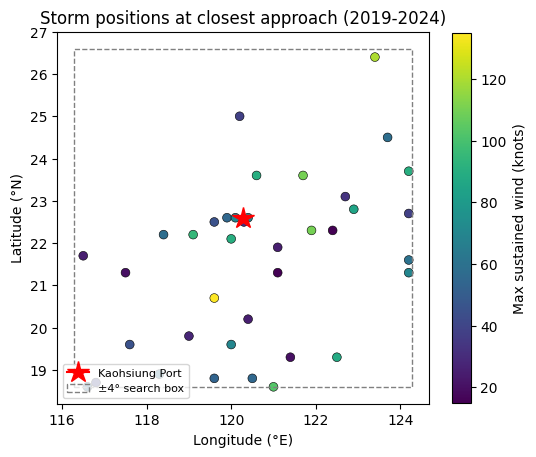

In [4]:
fig, ax = plt.subplots(figsize=(6, 6))
sc = ax.scatter(storms["LON"], storms["LAT"], c=pd.to_numeric(storms["USA_WIND"], errors="coerce"),
                cmap="viridis", s=40, edgecolor="k", lw=0.4)
ax.plot(cfg.PORT_LON, cfg.PORT_LAT, marker="*", color="red", ms=16, label="Kaohsiung Port")
box = cfg.STORM_BOX_DEG
ax.add_patch(plt.Rectangle((cfg.PORT_LON - box, cfg.PORT_LAT - box), 2 * box, 2 * box,
                           fill=False, ls="--", color="grey", label=f"±{box:.0f}° search box"))
ax.set_xlabel("Longitude (°E)")
ax.set_ylabel("Latitude (°N)")
ax.set_title("Storm positions at closest approach (2019-2024)")
ax.set_aspect("equal")
ax.legend(loc="lower left", fontsize=8)
fig.colorbar(sc, ax=ax, shrink=0.8, label="Max sustained wind (knots)")
plt.show()

  saved figures/storm_classification.png
  saved figures/storms_per_year.png


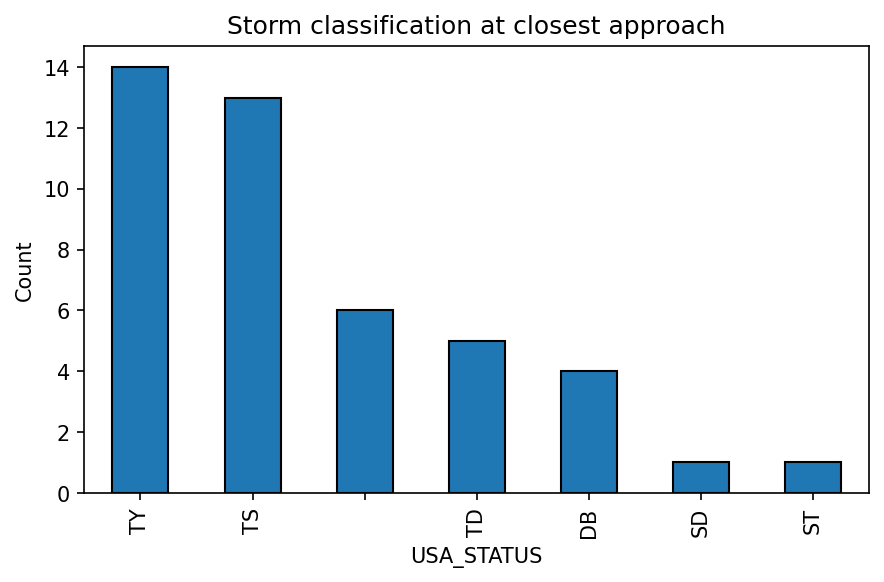

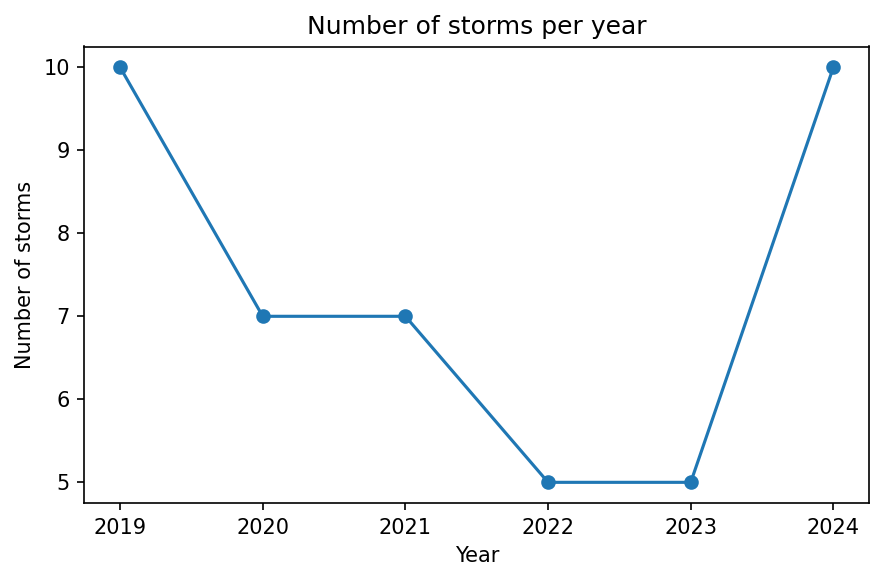

In [5]:
plots.storm_classification(storms)
plots.storms_per_year(storms)
show_figure("storm_classification.png")
show_figure("storms_per_year.png")

## 3. Layer 1: Initial analysis

Layer 1 uses two models:

1. **Cross-sectional OLS:** port activity volume vs storm conditions at closest approach (one observation per storm).
2. **Panel regression:** port activity volume vs daily weather at the ISD station (one observation per storm per day).

Each storm is given a 41-day window, from 10 days before to 30 days after the **calendar day** of its closest approach ($t = 0$).

In [6]:
daily = port[cfg.VESSEL_TYPES].copy()
daily["TOTAL_ARRIVALS"] = port["portcalls"]
panel1 = storm_panel(daily, storms)

print(f"{len(panel1)} storm-days across {panel1['SID'].nunique()} storms")
panel1.head()

1804 storm-days across 44 storms


,date,SID,days_from_approach,portcalls_container,portcalls_dry_bulk,portcalls_general_cargo,portcalls_roro,portcalls_tanker,TOTAL_ARRIVALS
0,2019-06-21,2019178N10137,-10,34,4,5,0,10,53
1,2019-06-22,2019178N10137,-9,24,6,3,1,5,39
2,2019-06-23,2019178N10137,-8,26,3,4,0,7,40
3,2019-06-24,2019178N10137,-7,20,4,4,1,9,38
4,2019-06-25,2019178N10137,-6,16,3,9,0,9,37


### 3.1 Cross-sectional OLS model

The first idea was a panel regression of storm conditions against port activity. However, IBTrACS only tracks a storm while it exists, which is much shorter than the 40-day window, so most storm-days would be missing. Instead, we model the **time-invariant conditions of the storm at closest approach** against the **trough of port activity** and the **time taken for port activity to recover**.

The storm conditions used are:

1. Maximum sustained wind speed, `USA_WIND` (knots)
2. Minimum central pressure, `USA_PRES` (hPa)
3. Radius of maximum wind, `USA_RMW` (nautical miles)
4. Distance of closest approach to the port, `DIST_FROM_PORT` (km)

**Pre-storm baseline.** To put all events on a common footing, each storm is first given a pre-storm baseline: its mean daily arrivals over days $-10$ to $-2$:

$$\bar{A}_i^{\text{base}} = \frac{1}{9}\sum_{t=-10}^{-2} A_{i,t}$$

where $i$ indexes the storm, $t$ is the day relative to closest approach, and $A_{i,t}$ is total arrivals.

**Trough.** The drop from baseline to the lowest point observed in the storm's window:

$$\text{Trough}_i = \bar{A}_i^{\text{base}} - \min_t A_{i,t}$$

**Recovery.** $\text{Recover}_i$ is the first day after closest approach on which arrivals get back to $\bar{A}_i^{\text{base}}$.

In [7]:
summary1 = layer1_storm_summary(panel1).merge(storms[["SID", "NAME", *cfg.STORM_VARS]], on="SID")
summary1[["NAME", "pre_storm_avg", "trough", "trough_drop", "days_to_recover", *cfg.STORM_VARS]].round(1)

,NAME,pre_storm_avg,trough,trough_drop,days_to_recover,USA_WIND,USA_PRES,USA_RMW,DIST_FROM_PORT
0,UNNAMED,43.2,30,13.2,4,15.0,1008.0,35.0,220.4
1,DANAS,41.3,17,24.3,2,38.0,989.0,45.0,402.4
2,LEKIMA,41.2,1,40.2,3,120.0,911.0,5.0,527.4
3,BAILU,42.9,1,41.9,1,55.0,981.0,35.0,39.0
4,KAJIKI,42.0,1,41.0,2,20.0,1003.0,50.0,384.9
5,LINGLING,42.8,1,41.8,2,70.0,979.0,15.0,429.3
6,UNNAMED,43.2,27,16.2,3,NaN,NaN,NaN,355.8
7,MITAG,41.4,23,18.4,3,85.0,968.0,30.0,269.7
8,KALMAEGI,40.9,27,13.9,2,88.0,965.0,15.0,433.3
9,FUNG-WONG,40.4,27,13.4,1,60.0,992.0,20.0,418.9


**Trough model:**

$$\text{Trough}_i = \beta_0 + \beta_1\,\text{WIND}_i + \beta_2\,\text{PRES}_i + \beta_3\,\text{RMW}_i + \beta_4\,\text{DIST}_i + \varepsilon_i$$

Storms without IBTrACS wind, pressure or radius data (mostly unnamed depressions) are dropped.

In [8]:
rhs = " + ".join(cfg.STORM_VARS)
data = summary1.dropna(subset=["trough_drop", *cfg.STORM_VARS])
ols_trough = smf.ols(f"trough_drop ~ {rhs}", data=data).fit()

print(f"N = {int(ols_trough.nobs)}, R² = {ols_trough.rsquared:.3f}, Adj. R² = {ols_trough.rsquared_adj:.3f}, "
      f"F({int(ols_trough.df_model)},{int(ols_trough.df_resid)}) = {ols_trough.fvalue:.3f}, p = {ols_trough.f_pvalue:.3f}")
coef_table(ols_trough)

N = 38, R² = 0.233, Adj. R² = 0.140, F(4,33) = 2.500, p = 0.061


,Coefficient,Std. Error,t-stat,p-value,,95% CI
Intercept,561.936,236.278,2.378,0.023,**,"[81.225, 1042.647]"
USA_WIND,-0.324,0.202,-1.603,0.119,,"[-0.735, 0.087]"
USA_PRES,-0.525,0.229,-2.295,0.028,**,"[-0.991, -0.060]"
USA_RMW,-0.086,0.186,-0.465,0.645,,"[-0.465, 0.292]"
DIST_FROM_PORT,-0.006,0.010,-0.568,0.574,,"[-0.026, 0.014]"


**Interpretation.** Central pressure is the only statistically significant predictor of trough size ($\beta_2 \approx -0.53$, $p \approx 0.03$). Lower pressure, meaning a more intense storm, goes with a deeper drop in arrivals relative to baseline. Wind speed points the same way but is not significant, and storm size and distance are not significant either.

The model explains about 23% of the variation in trough size, but it is only marginally significant overall ($p \approx 0.06$). With 38 storms and four correlated intensity measures, the model has limited power.

**Recovery model:**

$$\text{Recover}_i = \gamma_0 + \gamma_1\,\text{WIND}_i + \gamma_2\,\text{PRES}_i + \gamma_3\,\text{RMW}_i + \gamma_4\,\text{DIST}_i + u_i$$

This model is fitted only on storms where $\text{Recover}_i$ is defined. Storms that never recovered within the window are dropped.

In [9]:
data = summary1.dropna(subset=["days_to_recover", *cfg.STORM_VARS])
ols_recover = smf.ols(f"days_to_recover ~ {rhs}", data=data).fit()

print(f"N = {int(ols_recover.nobs)}, R² = {ols_recover.rsquared:.3f}, Adj. R² = {ols_recover.rsquared_adj:.3f}, "
      f"F({int(ols_recover.df_model)},{int(ols_recover.df_resid)}) = {ols_recover.fvalue:.3f}, p = {ols_recover.f_pvalue:.3f}")
coef_table(ols_recover)

N = 38, R² = 0.106, Adj. R² = -0.002, F(4,33) = 0.979, p = 0.432


,Coefficient,Std. Error,t-stat,p-value,,95% CI
Intercept,27.605,30.459,0.906,0.371,,"[-34.363, 89.573]"
USA_WIND,-0.022,0.026,-0.840,0.407,,"[-0.075, 0.031]"
USA_PRES,-0.025,0.030,-0.854,0.399,,"[-0.085, 0.035]"
USA_RMW,0.001,0.024,0.026,0.979,,"[-0.048, 0.049]"
DIST_FROM_PORT,0.002,0.001,1.702,0.098,*,"[-0.000, 0.005]"


**Interpretation.** None of the four storm characteristics significantly predicts recovery time, and the model as a whole is not significant. The adjusted R² is about zero, so the model does no better than predicting the mean. Within this sample, storm intensity or proximity alone does not explain how quickly activity recovers.

### 3.2 Panel regression

Unlike the storm tracks, the Kaohsiung weather station records every day of the 41-day window. This lets us model the **time-varying weather conditions** at the port against the **time-varying port activity**. Two variables are used, mainly because they are available for almost every day:

1. Mean wind speed, `WDSP` (knots)
2. Visibility, `VISIB` (miles)

$$\text{TOTAL\_ARRIVALS}_{i,t} = \alpha_i + \beta_1\,\text{WDSP}_{i,t} + \beta_2\,\text{VISIB}_{i,t} + \varepsilon_{i,t}$$

where:

- $i$ indexes the storm (the entity) and $t$ the day relative to closest approach (the time dimension).
- $\alpha_i$ is a storm fixed effect, which absorbs anything about the storm that doesn't change over time.
- Standard errors are clustered by storm.

In [10]:
p1 = panel1.merge(weather[["WDSP", "VISIB"]], left_on="date", right_index=True, how="left")
p1 = p1.dropna(subset=["TOTAL_ARRIVALS", "WDSP", "VISIB"]).set_index(["SID", "days_from_approach"])

panel_l1 = PanelOLS.from_formula("TOTAL_ARRIVALS ~ WDSP + VISIB + EntityEffects", data=p1) \
    .fit(cov_type="clustered", cluster_entity=True)

print(f"N = {panel_l1.nobs}, Entities = {panel_l1.entity_info['total']:.0f}, "
      f"R² (within) = {panel_l1.rsquared_within:.3f}, "
      f"F-test for poolability = {panel_l1.f_pooled.stat:.2f} (p {'< 0.001' if panel_l1.f_pooled.pval < 0.001 else '= %.3f' % panel_l1.f_pooled.pval})")
coef_table(panel_l1)

N = 1779, Entities = 44, R² (within) = 0.185, F-test for poolability = 8.88 (p < 0.001)


,Coefficient,Std. Error,t-stat,p-value,,95% CI
WDSP,-1.547,0.109,-14.231,0.0,***,"[-1.760, -1.334]"
VISIB,2.360,0.361,6.546,0.0,***,"[1.653, 3.067]"


**Interpretation.** Daily wind speed and visibility are both highly significant ($p < 0.001$), holding each storm's own baseline constant:

- Each extra knot of mean wind speed goes with about **1.5 fewer arrivals per day**.
- Each extra mile of visibility goes with about **2.4 more arrivals per day**.
- The model explains about 19% of the variation in daily arrivals within each storm.
- The poolability F-test ($p < 0.001$) shows the storm fixed effects are justified, so a panel design is better than a single pooled regression.

### 3.3 Layer 1 conclusion

The cross-sectional model suggests that storm intensity, particularly central pressure, is linked to how deep the disruption is, but not to how quickly activity recovers. The panel model gives stronger and more consistent evidence: local weather (wind speed and visibility) is a significant driver of day-to-day changes in arrivals throughout a storm's approach and aftermath. Overall storm severity has some relationship with the scale of disruption, but the daily pattern is better explained by real-time conditions at the port itself.

## 4. Layer 2: Refinement using time-series normalisation

Layer 1 measured disruption against each storm's own short pre-storm average. That average is noisy, because port calls have a strong weekly cycle and a slow trend, and it is contaminated when storms come back to back. Layer 2 instead builds a **time-series model of normal port activity**, fitted only on days unaffected by storms. It then measures disruption as the deviation from that counterfactual.

  saved figures/layer2_flowchart.png


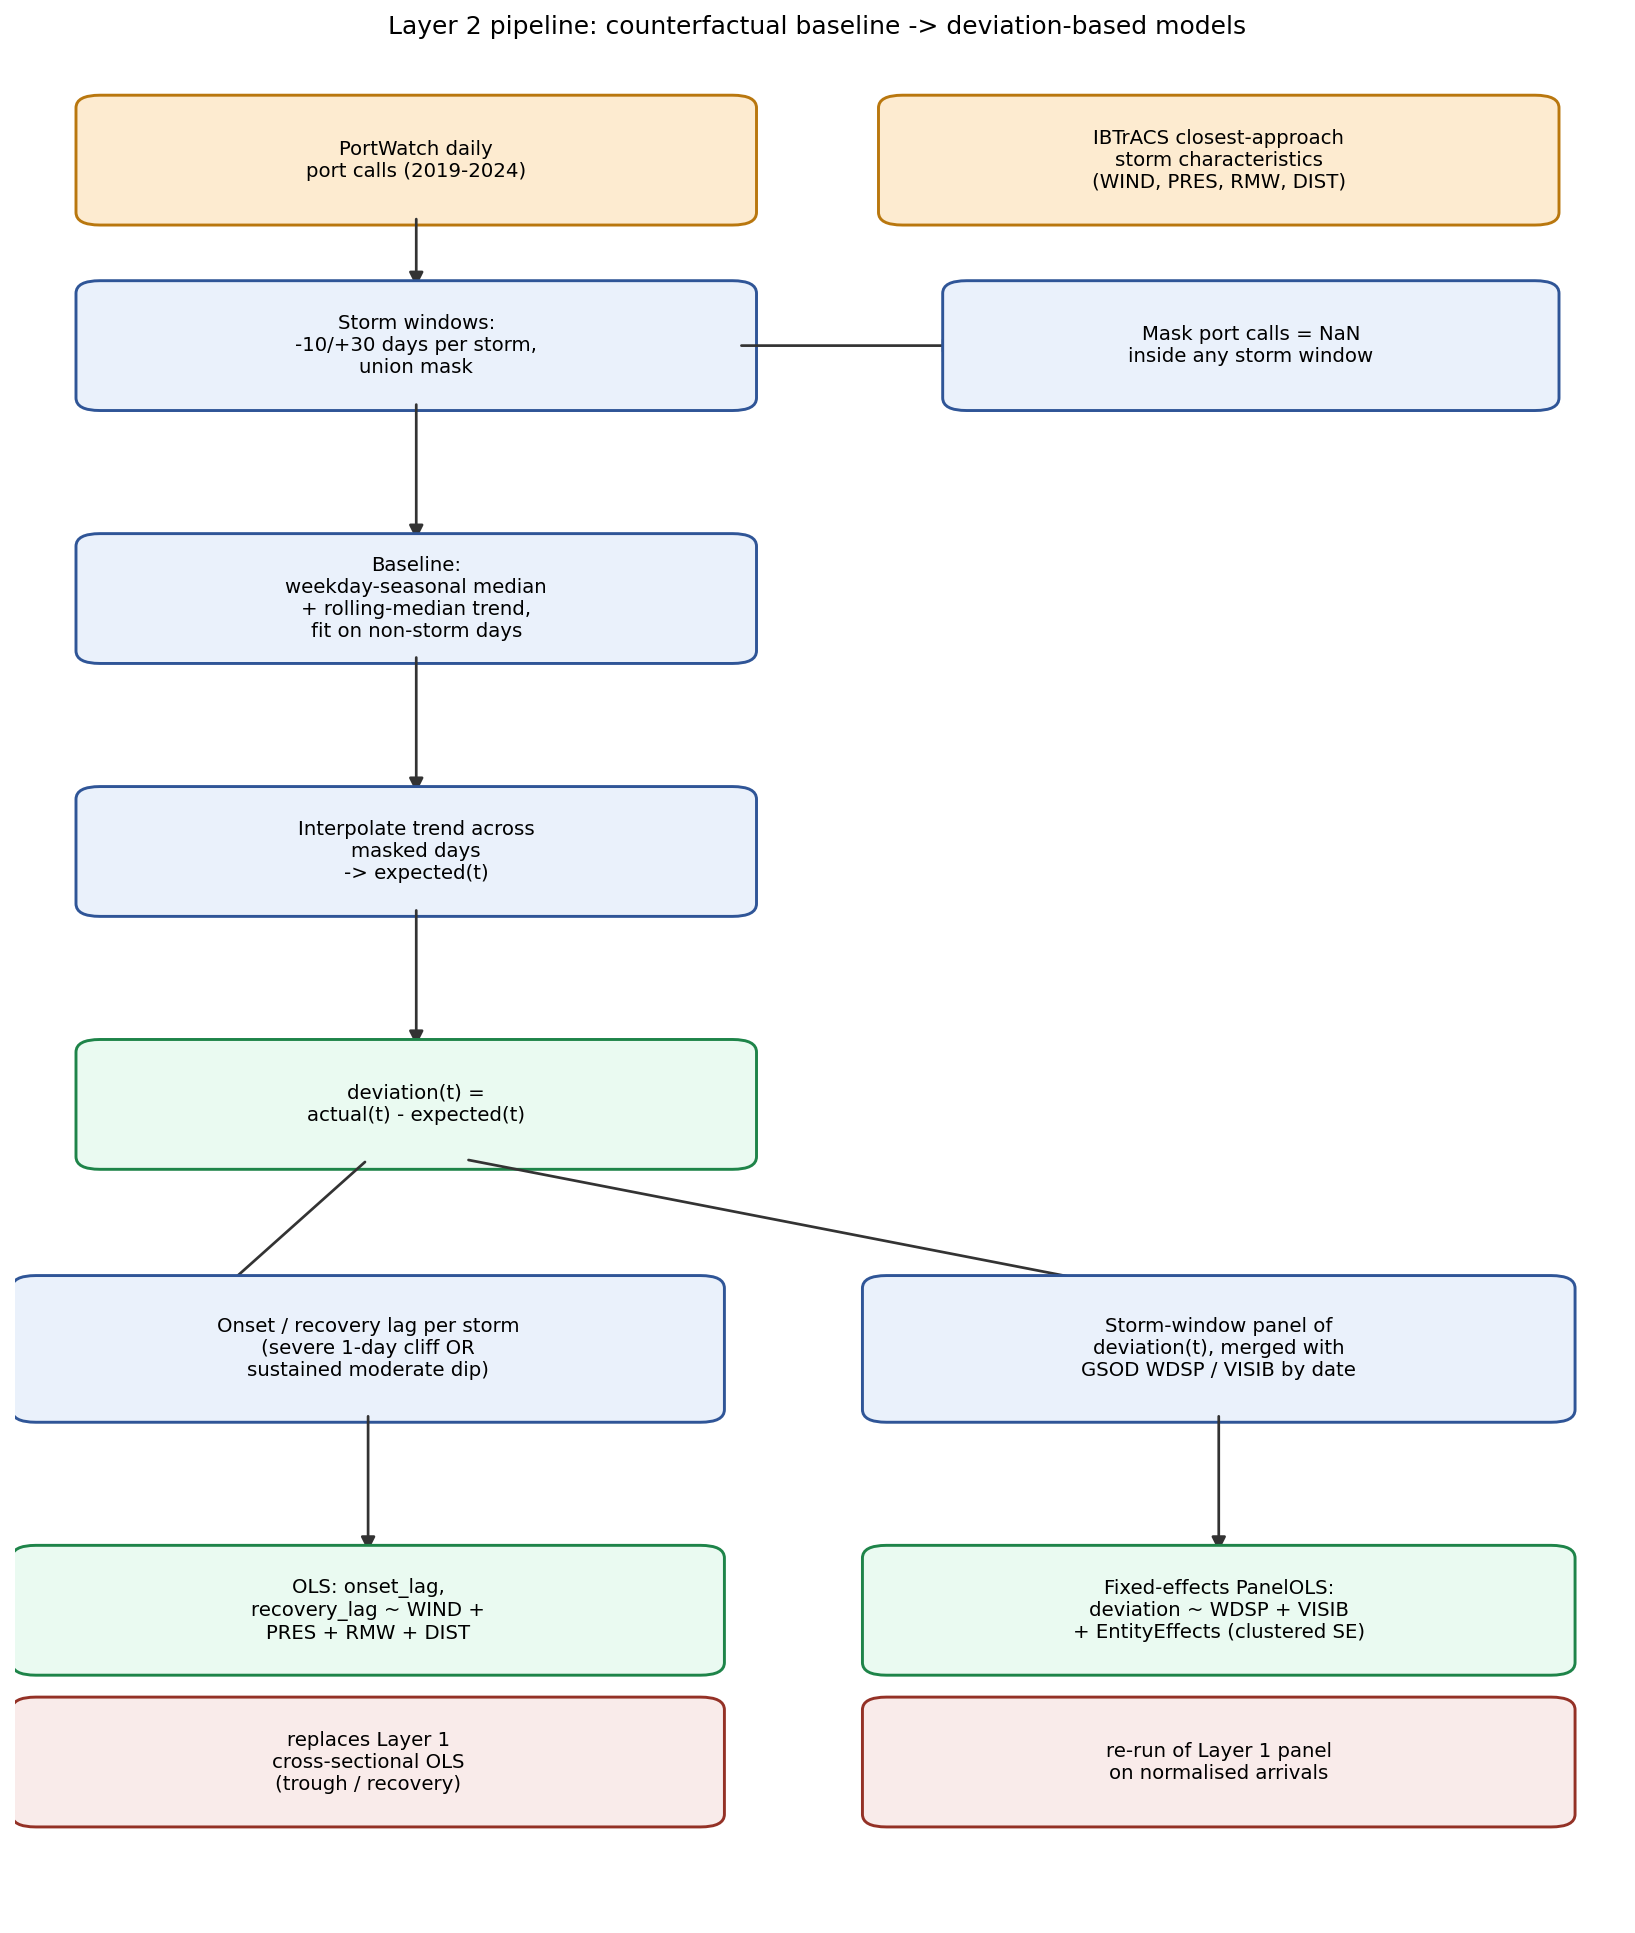

In [11]:
plots.pipeline_flowchart()
show_figure("layer2_flowchart.png")

### 4.1 Time-series model

**Seasonal component.** The autocorrelation function of daily port calls has spikes at lags 7, 14, 21, … (orange lines), which shows a 7-day weekly cycle.

  saved figures/acf_port_calls.png


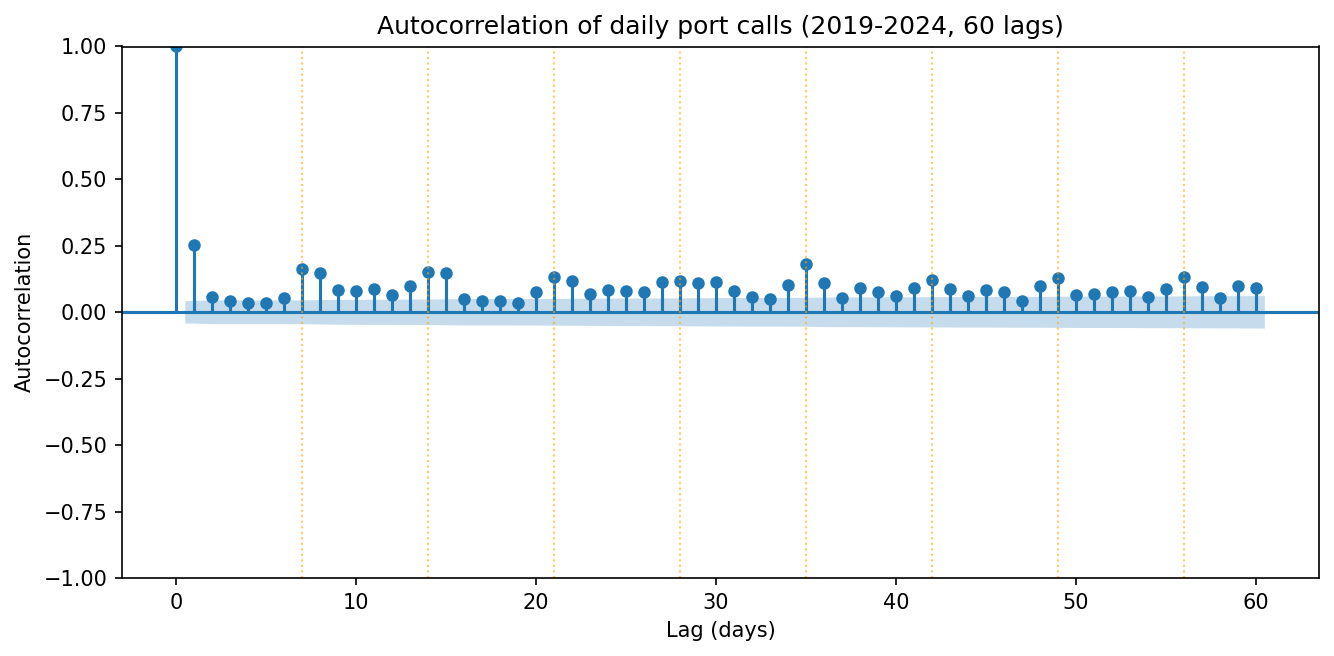

In [12]:
plots.acf_port_calls(port)
show_figure("acf_port_calls.png")

**Model.** The baseline is a simple decomposition fitted only on non-storm days:

1. Mask every day inside any storm's $-10/+30$ day window. With 44 overlapping windows, this removes about 45% of all days.
2. **Seasonal:** the median port calls for each day of the week, using unmasked days only.
3. **Trend:** deseasonalise the unmasked series and smooth it with a centred 29-day rolling median. Then interpolate it linearly across the masked days, keeping it flat at the two ends of the series.

$$\text{Expected}(t) = \text{Trend}(t) + \text{Seasonal}[\text{weekday}(t)]$$
$$\text{Deviation}(t) = \text{Actual}(t) - \text{Expected}(t)$$

An ARIMA-type model was tried first. With so many days masked, its autoregressive terms drifted downward through long gaps instead of holding a stable baseline. The rolling-median approach has no such memory, so it cannot drift.

In [13]:
cf, sigma, seasonal = build_counterfactual(port, storms)

print(f"Days inside a storm window: {cf['in_storm_window'].sum()} of {len(cf)} ({cf['in_storm_window'].mean():.1%})")
print(f"Residual std on non-storm days (sigma): {sigma:.2f} port calls/day\n")
print("Weekday seasonal component (median port calls):")
seasonal.rename(index=dict(enumerate(["Mon", "Tue", "Wed", "Thu", "Fri", "Sat", "Sun"]))).to_frame("median")

Days inside a storm window: 990 of 2192 (45.2%)
Residual std on non-storm days (sigma): 6.13 port calls/day

Weekday seasonal component (median port calls):


,median
weekday,
Mon,38.0
Tue,35.0
Wed,37.0
Thu,38.0
Fri,39.0
Sat,35.0
Sun,37.0


  saved figures/layer2_full_timeline.png


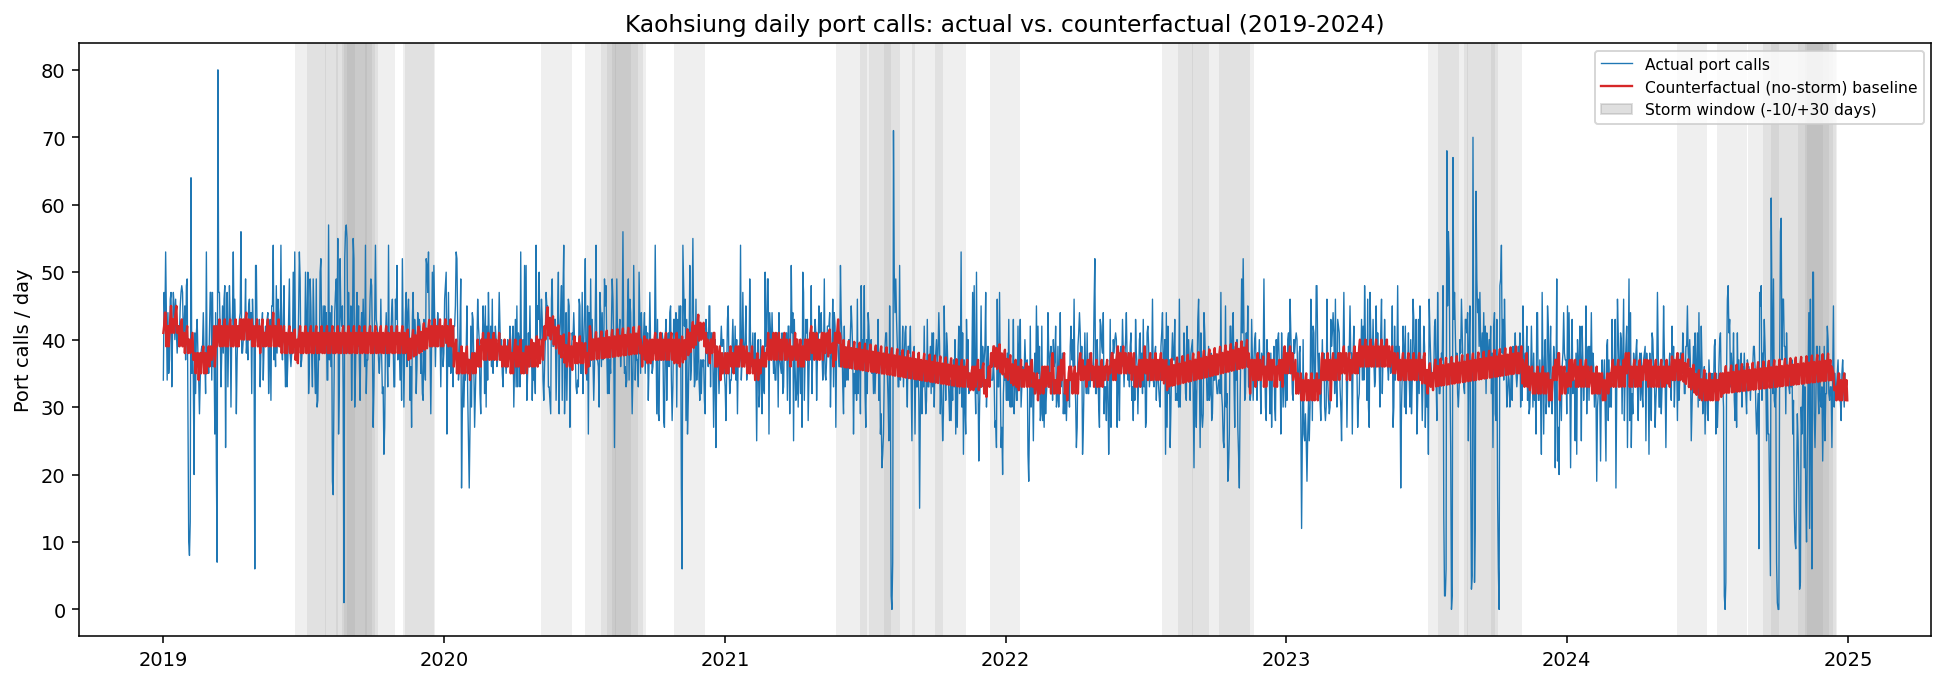

In [14]:
plots.full_timeline(cf, storm_windows(storms))
show_figure("layer2_full_timeline.png")

### 4.2 Disruption timing: onset and recovery

With a counterfactual in place, the timing of each storm's disruption can be measured directly. $\sigma$ is the residual standard deviation on non-storm days.

- **Onset** is the first day in the window when activity falls meaningfully below the baseline, by whichever rule triggers first:
  - (a) a severe single-day cliff: deviation $< -3\sigma$
  - (b) a sustained moderate dip: deviation $< -1.5\sigma$ for at least 2 consecutive days
- **Recovery** is the first day after onset when deviation is back above $-1.5\sigma$.

Rule (a) matters at Kaohsiung. Typhoon closures there are often a single-day stop followed at once by a catch-up surge, as queued ships all arrive together. Typhoon Krathon, which made landfall at Kaohsiung in October 2024, shows this pattern clearly:

  saved figures/layer2_storm_example.png


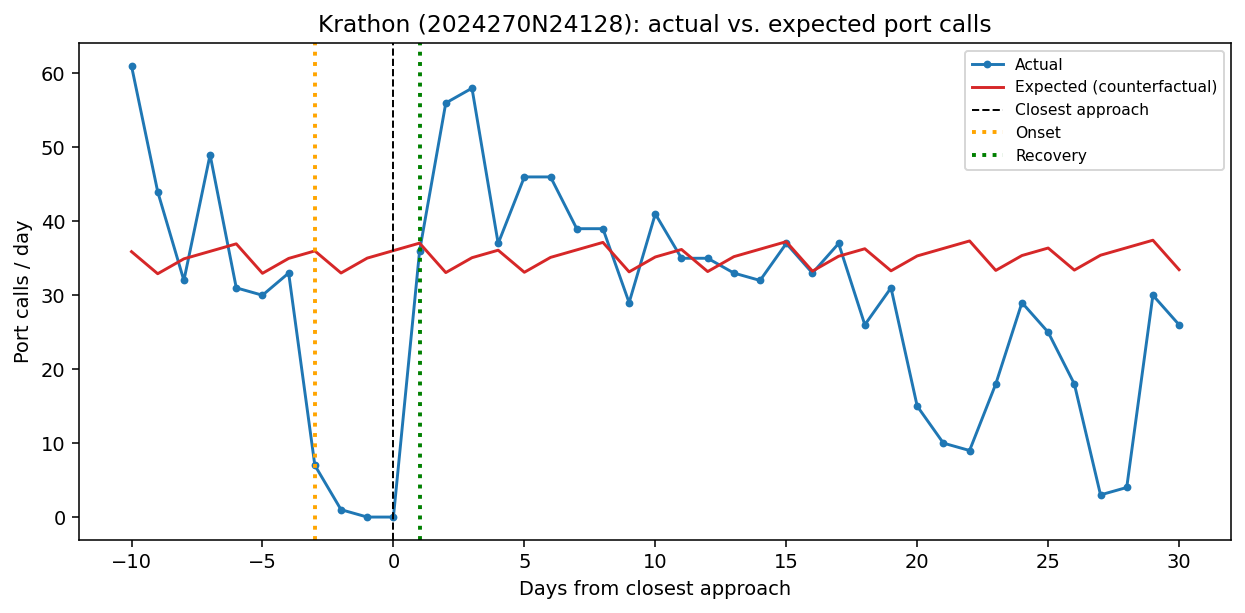

In [15]:
panel2 = storm_panel(cf[["portcalls", "expected", "deviation"]], storms)
lags = detect_onset_recovery(panel2, sigma).merge(storms[["SID", "NAME", *cfg.STORM_VARS]], on="SID")

plots.storm_example(panel2, lags[lags["NAME"] == cfg.EXAMPLE_STORM].iloc[0], cfg.EXAMPLE_STORM)
show_figure("layer2_storm_example.png")

Onset detected for 29/44 storms
Median onset -2 days, median recovery +1 days, median duration 3 days


  saved figures/layer2_lag_distributions.png


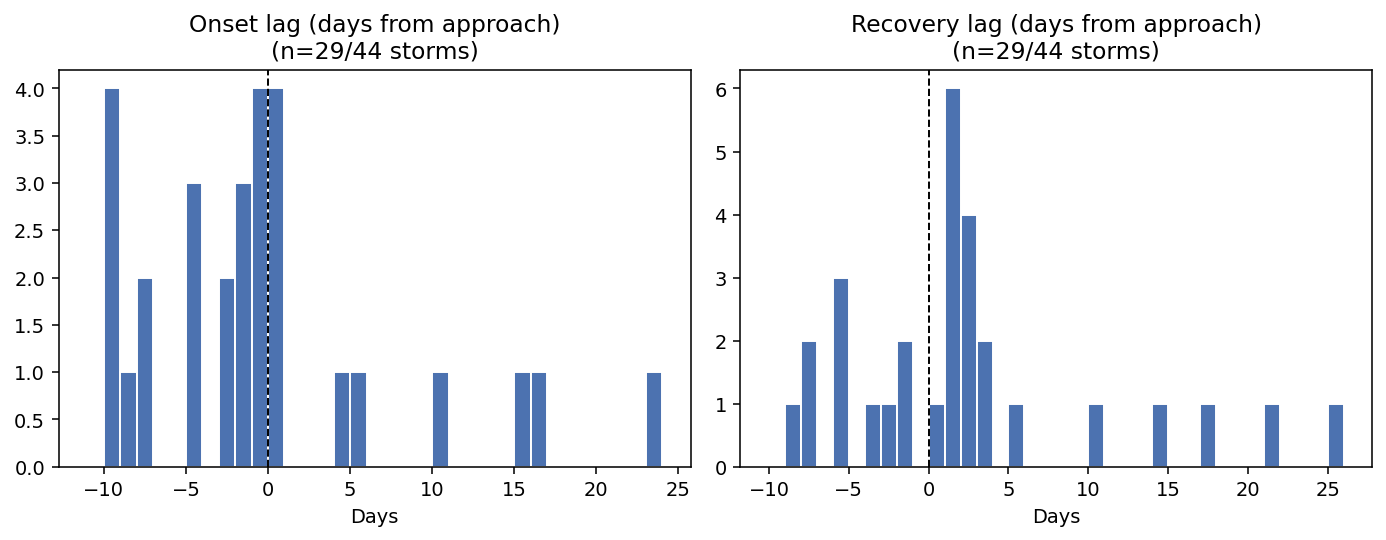

In [16]:
n = len(lags)
print(f"Onset detected for {lags['onset_lag'].notna().sum()}/{n} storms")
print(f"Median onset {lags['onset_lag'].median():+.0f} days, median recovery {lags['recovery_lag'].median():+.0f} days, "
      f"median duration {lags['duration_days'].median():.0f} days")
plots.lag_distributions(lags)
show_figure("layer2_lag_distributions.png")

Disruption is typically short and sharp. The median onset is about 2 days before closest approach, and activity is usually back to normal within 2–4 days. This is a brief dip rather than a prolonged slump.

The onset and recovery lags are then regressed on the same storm characteristics as in Layer 1. This replaces the Layer 1 trough and recovery measures, which were based on the pre-storm average:

In [17]:
lag_models = {}
for target in ["onset_lag", "recovery_lag", "duration_days"]:
    data = lags.dropna(subset=[target, *cfg.STORM_VARS])
    lag_models[target] = smf.ols(f"{target} ~ {rhs}", data=data).fit()

pd.DataFrame({
    t: {"N": int(m.nobs), "R²": m.rsquared, "Adj. R²": m.rsquared_adj, "F p-value": m.f_pvalue,
        **{f"p({v})": m.pvalues[v] for v in cfg.STORM_VARS}}
    for t, m in lag_models.items()
}).T.round(3)

,N,R²,Adj. R²,F p-value,p(USA_WIND),p(USA_PRES),p(USA_RMW),p(DIST_FROM_PORT)
onset_lag,26.0,0.173,0.016,0.382,0.758,0.307,0.129,0.986
recovery_lag,26.0,0.183,0.028,0.349,0.733,0.269,0.113,0.846
duration_days,26.0,0.111,-0.058,0.628,0.820,0.552,0.671,0.177


None of these regressions is significant. With complete port data, this looks like a genuine sample-size limit rather than a data-quality problem: only 44 storms pass close enough to study, and only 26 of them have both a detectable onset and complete storm characteristics. The same caveat applies to Layer 1's cross-sectional model.

### 4.3 Panel regression using normalised port activity

This is a re-run of Layer 1's panel regression. In Layer 1 the dependent variable was raw `TOTAL_ARRIVALS`, so the storm fixed effects had to absorb both each storm's baseline level and its weekly pattern. Here the dependent variable is $\text{Deviation}(t)$, so the trend and weekly seasonality are removed before the panel sees the data:

$$\text{Deviation}_{i,t} = \alpha_i + \beta_1\,\text{WDSP}_{i,t} + \beta_2\,\text{VISIB}_{i,t} + \varepsilon_{i,t}$$

In [18]:
daily2 = cf[["portcalls", "expected", "deviation"]].join(weather[["WDSP", "VISIB"]])
p2 = storm_panel(daily2, storms).dropna(subset=["deviation", "WDSP", "VISIB"]) \
    .set_index(["SID", "days_from_approach"])

panel_l2 = PanelOLS.from_formula("deviation ~ WDSP + VISIB + EntityEffects", data=p2) \
    .fit(cov_type="clustered", cluster_entity=True)

print(f"N = {panel_l2.nobs}, Entities = {panel_l2.entity_info['total']:.0f}, "
      f"R² (within) = {panel_l2.rsquared_within:.3f}, "
      f"F-test for poolability = {panel_l2.f_pooled.stat:.2f} (p {'< 0.001' if panel_l2.f_pooled.pval < 0.001 else '= %.3f' % panel_l2.f_pooled.pval})")
coef_table(panel_l2)

N = 1779, Entities = 44, R² (within) = 0.191, F-test for poolability = 3.55 (p < 0.001)


,Coefficient,Std. Error,t-stat,p-value,,95% CI
WDSP,-1.566,0.113,-13.922,0.0,***,"[-1.787, -1.346]"
VISIB,2.395,0.343,6.978,0.0,***,"[1.722, 3.068]"


In [19]:
# Side-by-side: Layer 1 (raw arrivals) vs Layer 2 (deviation from counterfactual)
pd.DataFrame({
    "Layer 1: raw arrivals": [panel_l1.params["WDSP"], panel_l1.params["VISIB"], panel_l1.nobs, panel_l1.rsquared_within],
    "Layer 2: deviation": [panel_l2.params["WDSP"], panel_l2.params["VISIB"], panel_l2.nobs, panel_l2.rsquared_within],
}, index=["WDSP coefficient", "VISIB coefficient", "N", "R² (within)"]).round(3)

,Layer 1: raw arrivals,Layer 2: deviation
WDSP coefficient,-1.547,-1.566
VISIB coefficient,2.360,2.395
N,1779.000,1779.000
R² (within),0.185,0.191


**Interpretation.** Wind speed and visibility stay highly significant, with the same signs as in Layer 1 and almost identical sizes (about −1.57 and +2.40, against −1.55 and +2.36). This is a strong robustness check. The weather relationship found in Layer 1 is not an artefact of using each storm's own short pre-storm baseline: it holds up essentially unchanged when arrivals are normalised against a model-based counterfactual that doesn't depend on any storm.

## 5. Conclusions and limitations

### 5.1 Conclusions

- **Local weather drives daily disruption.** In both layers, each extra knot of wind speed costs about 1.5 port calls per day and each extra mile of visibility adds about 2.4. This holds whether activity is measured raw or against a no-storm counterfactual.
- **Disruption is short and sharp.** Compared with the counterfactual, a typical storm produces a dip lasting 2–4 days around closest approach, often a one-day closure followed by a catch-up surge, rather than a prolonged slump.
- **Storm-level characteristics explain little.** Central pressure is linked to how deep the trough is in Layer 1. However, neither the depth, timing nor duration of disruption is reliably predicted by storm intensity or proximity. With at most 38 usable storms, these models have limited power.

### 5.2 Limitations and further work

- **Overlapping storm windows.** Back-to-back storms share days. For example, Krathon, Kong-rey, Yinxing, Toraji, Man-yi and Usagi all fall between October and November 2024. The same drop in port calls can then be counted as the onset for several storms, sometimes at the edge of a window. Possible fixes are to narrow the onset search (e.g. −3 to +7 days) or to give each day only to its nearest storm.
- **Sample size.** Only 44 storms pass within the search box in 2019–2024, a limit set by how far back PortWatch data goes. Extending the study to other ports, such as Keelung, Taichung, Hong Kong or Xiamen, would add many more events.
- **Weather variables.** Only wind speed and visibility are complete enough to use. Daily precipitation and gusts have many gaps, and hourly ISD data could capture conditions during the actual closure hours.